### Important Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error, r2_score, root_mean_squared_log_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

### Import Dataset

In [2]:
train = pd.read_csv('train.csv')
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
train.shape

(1460, 81)

- There is data of 1460 Houses and 81 features in the training dataset. 

In [4]:
# show only columns with missing values
missing_values = train.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values.sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [5]:
train['PoolQC'].sample(10)

548     NaN
513     NaN
351     NaN
1427    NaN
1065    NaN
1169    NaN
1120    NaN
209     NaN
515     NaN
1129    NaN
Name: PoolQC, dtype: str

- There are `1453` missing values in the `PoolQC` column. This is a categorical feature that describes the quality of the pool. The missing values in this column indicate that the house does not have a pool. We will fill the missing values with the string `No Pool` to indicate that these houses do not have a pool. 

In [6]:
train['MiscFeature'].sample(10)

1438    NaN
1429    NaN
714     NaN
737     NaN
1287    NaN
1128    NaN
516     NaN
645     NaN
0       NaN
287     NaN
Name: MiscFeature, dtype: str

- We will fill 1406 missing values in the `MiscFeature` column with the string `None` to indicate that these houses do not have any miscellaneous features.

In [7]:
train['Alley'].sample(10)

611     NaN
1013    NaN
282     NaN
1204    NaN
1441    NaN
345     NaN
692     NaN
472     NaN
14      NaN
1243    NaN
Name: Alley, dtype: str

- There are `1369` missing values in the `Alley` column. This is a categorical feature that describes the type of alley access to the property. The missing values in this column indicate that the house does not have alley access. We will fill the missing values with the string `No Alley` to indicate that these houses do not have alley access.

In [8]:
# Rows where MasVnrType and MasVnrArea both are missing
train.loc[train['MasVnrType'].isnull() & train['MasVnrArea'].isnull(), ['Id', 'MasVnrType', 'MasVnrArea']]

,Id,MasVnrType,MasVnrArea
234,235,NaN,NaN
529,530,NaN,NaN
650,651,NaN,NaN
936,937,NaN,NaN
973,974,NaN,NaN
977,978,NaN,NaN
1243,1244,NaN,NaN
1278,1279,NaN,NaN


- It looks like there 8 houses with missing masonry veneer type and area do not have and masonaary veneer. We will fill the missing values in the `MasVnrType` column with the string `None` and the missing values in the `MasVnrArea` column with 0 to indicate that these houses do not have any masonry veneer.

In [9]:
train['FireplaceQu'].sample(10)

1443     Gd
213     NaN
1069    NaN
9        TA
810      Fa
985     NaN
808      Gd
3        Gd
924      TA
148     NaN
Name: FireplaceQu, dtype: str

- There are `690` missing values in the `FireplaceQu` column. This is a categorical feature that describes the quality of the fireplace. The missing values in this column indicate that the house does not have a fireplace. We will fill the missing values with the string `No Fireplace` to indicate that these houses do not have a fireplace.

- Columns GarageType, GarageYrBlt, GarageFinish, GarageQual, and GarageCond all have 81 missing values. Let's check if these missing values are for the same houses.

In [10]:
# check for the houses with missing garage information
garage_missing = train[train['GarageType'].isnull() & train['GarageYrBlt'].isnull() & train['GarageFinish'].isnull() & train['GarageQual'].isnull() & train['GarageCond'].isnull()]
garage_missing[['Id', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond']]

,Id,GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond
39,40,NaN,NaN,NaN,NaN,NaN
48,49,NaN,NaN,NaN,NaN,NaN
78,79,NaN,NaN,NaN,NaN,NaN
88,89,NaN,NaN,NaN,NaN,NaN
89,90,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
1349,1350,NaN,NaN,NaN,NaN,NaN
1407,1408,NaN,NaN,NaN,NaN,NaN
1449,1450,NaN,NaN,NaN,NaN,NaN
1450,1451,NaN,NaN,NaN,NaN,NaN


- We will fill the missing values with the string `No Garage` to indicate that these houses do not have a garage.

- In features BsmtExposure and BsmtFinType2, there are 38 missing values. Similarly, in features BsmtQual, BsmtCond, and BsmtFinType1, there are 37 missing values. Let's check if atleast 37 of these missing values are for the same houses.

In [11]:
# check for the houses with missing basement information
basement_missing = train[train['BsmtQual'].isnull() & train['BsmtCond'].isnull() & train['BsmtExposure'].isnull() & train['BsmtFinType1'].isnull() & train['BsmtFinType2'].isnull()]
print(basement_missing[['Id', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']])
print(basement_missing.info())

        Id BsmtQual BsmtCond BsmtExposure BsmtFinType1 BsmtFinType2
17      18      NaN      NaN          NaN          NaN          NaN
39      40      NaN      NaN          NaN          NaN          NaN
90      91      NaN      NaN          NaN          NaN          NaN
102    103      NaN      NaN          NaN          NaN          NaN
156    157      NaN      NaN          NaN          NaN          NaN
182    183      NaN      NaN          NaN          NaN          NaN
259    260      NaN      NaN          NaN          NaN          NaN
342    343      NaN      NaN          NaN          NaN          NaN
362    363      NaN      NaN          NaN          NaN          NaN
371    372      NaN      NaN          NaN          NaN          NaN
392    393      NaN      NaN          NaN          NaN          NaN
520    521      NaN      NaN          NaN          NaN          NaN
532    533      NaN      NaN          NaN          NaN          NaN
533    534      NaN      NaN          NaN       

- It's confirmed that all the missing values in the basement features are for the same houses. We will fill the missing values with the string `No Basement` to indicate that these houses do not have a basement.

#### Handling missing values

In [12]:
def handle_missing_values(train):

    train = train.copy()
    # test = test.copy()

    # 1. LotFrontage: Median grouped by Neighborhood
    neighborhood_median = train.groupby("Neighborhood")["LotFrontage"].median()
    global_median = train["LotFrontage"].median()

    train["LotFrontage"] = train["LotFrontage"].fillna(
        train["Neighborhood"].map(neighborhood_median)
    ).fillna(global_median)

    # test["LotFrontage"] = test["LotFrontage"].fillna(
        # test["Neighborhood"].map(neighborhood_median)).fillna(global_median)

    # 2. Identify categorical and numerical columns
    categorical_cols = train.select_dtypes(
        include=["object", "category", "string"]
    ).columns

    numerical_cols = train.select_dtypes(
        include="number"
    ).columns

    # 3. Fill categorical missing values with "None"
    for col in categorical_cols:
        train[col] = train[col].fillna("None")

        #if col in test.columns:
            # test[col] = test[col].fillna("None")

    # 4. Fill numerical missing values with 0
    for col in numerical_cols:
        train[col] = train[col].fillna(0)

        # if col in test.columns:
            #test[col] = test[col].fillna(0)

    return train, #test


# Apply preprocessing
# Recover the DataFrame if the cell was previously executed
if isinstance(train, tuple):
    train = train[0]

train = handle_missing_values(train)[0]
# test = handle_missing_values(test)


# 5. Check remaining missing values
print("Remaining missing values:", train.isnull().sum().sum())
print(train.isnull().sum()[train.isnull().sum() > 0])
# print("Test missing values:", test.isnull().sum().sum())

Remaining missing values: 0
Series([], dtype: int64)


#### Analyzing Target Variable 

In [13]:
train['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

<Axes: xlabel='SalePrice', ylabel='Density'>

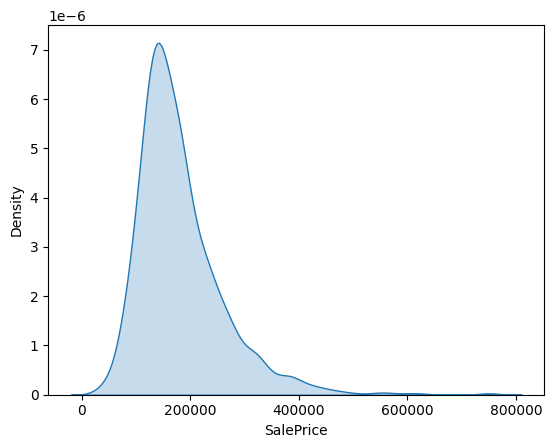

In [14]:
sns.kdeplot(data=train, x="SalePrice", fill=True)

<Axes: xlabel='SalePrice'>

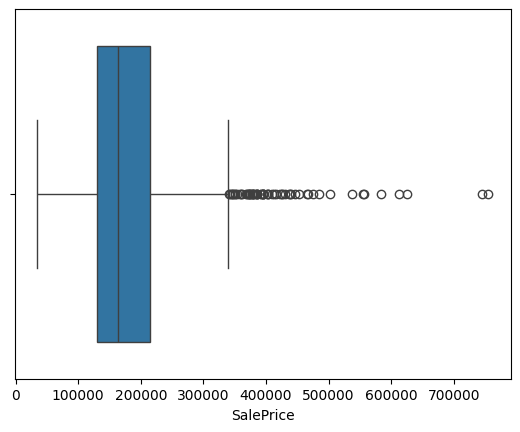

In [15]:
sns.boxplot(data=train, x="SalePrice")

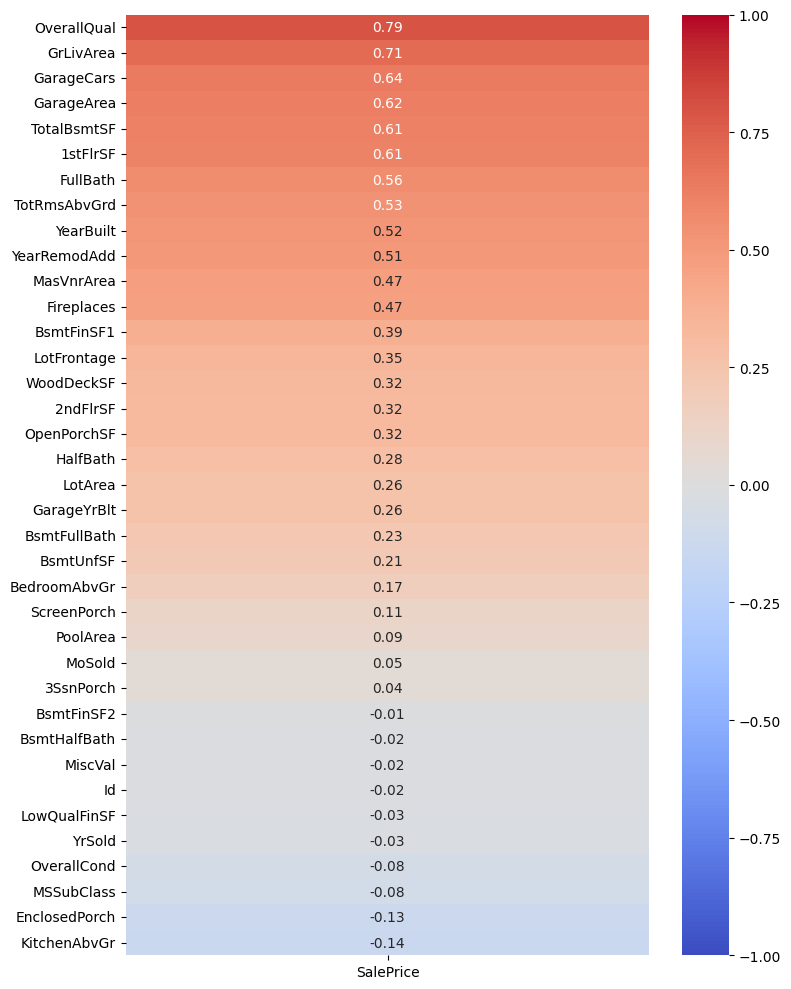

In [16]:
# Select only numerical features
numeric_df = train.select_dtypes(include=[np.number])

# Calculate correlation with respect to 'SalePrice' and sort values descending
corr_matrix = numeric_df.corr()
saleprice_corr = corr_matrix[['SalePrice']].sort_values(
    by='SalePrice', ascending=False
).drop('SalePrice')

# Set up the figure size
plt.figure(figsize=(8, 10))

# Create the heatmap
sns.heatmap(
    saleprice_corr,
    annot=True,  # Display the correlation values
    fmt='.2f',  # Format values to 2 decimal places
    cmap='coolwarm',  # Red-to-blue colormap
    vmin=-1.0,  # Minimum value for colorbar scale
    vmax=1.0,  # Maximum value for colorbar scale
    cbar=True,  # Include colorbar
)

# Adjust layout to fit y-labels comfortably
plt.tight_layout()
plt.show()

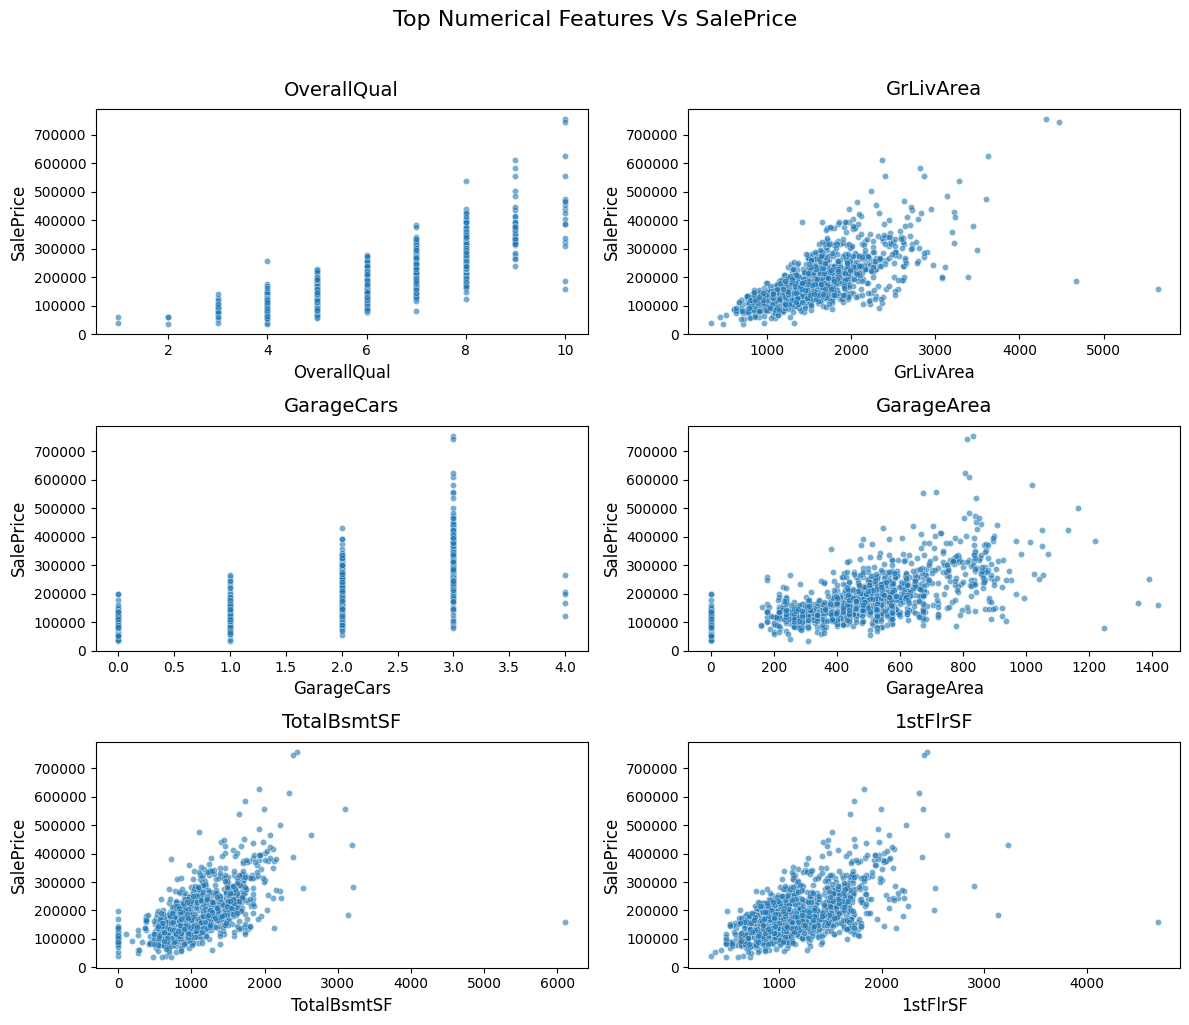

In [17]:
# scatterplot of SalePrice with top 6 correlated features
features = saleprice_corr.index[:6]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12,10))

axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, feature in enumerate(features):
    sns.scatterplot(data=train, x=feature, y='SalePrice', ax=axes[i], alpha=0.6, s=20)
    axes[i].set_title(feature, fontsize = 14, pad = 10)
    axes[i].set_xlabel(feature, fontsize = 12)
    axes[i].set_ylabel('SalePrice', fontsize = 12)

fig.suptitle("Top Numerical Features Vs SalePrice", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [18]:
condition = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
print(train.loc[condition, ["OverallQual", "OverallCond", "YearBuilt",
    "Neighborhood", "SaleCondition", "KitchenQual", "ExterQual"]])


train.loc[condition, ["GrLivArea", "LotArea", "1stFlrSF", "2ndFlrSF", "TotalBsmtSF", "GarageArea"]
]

      OverallQual  OverallCond  YearBuilt Neighborhood SaleCondition  \
523            10            5       2007      Edwards       Partial   
1298           10            5       2008      Edwards       Partial   

     KitchenQual ExterQual  
523           Ex        Ex  
1298          Ex        Ex  


,GrLivArea,LotArea,1stFlrSF,2ndFlrSF,TotalBsmtSF,GarageArea
523,4676,40094,3138,1538,3138,884
1298,5642,63887,4692,950,6110,1418


- Two Houses with GrLivArea greater than 4000 have unusually low SalePrice value despite hight quality ratings and recent construction years. 
- These observations are houses are potential outliers, but we will not remove them yet.

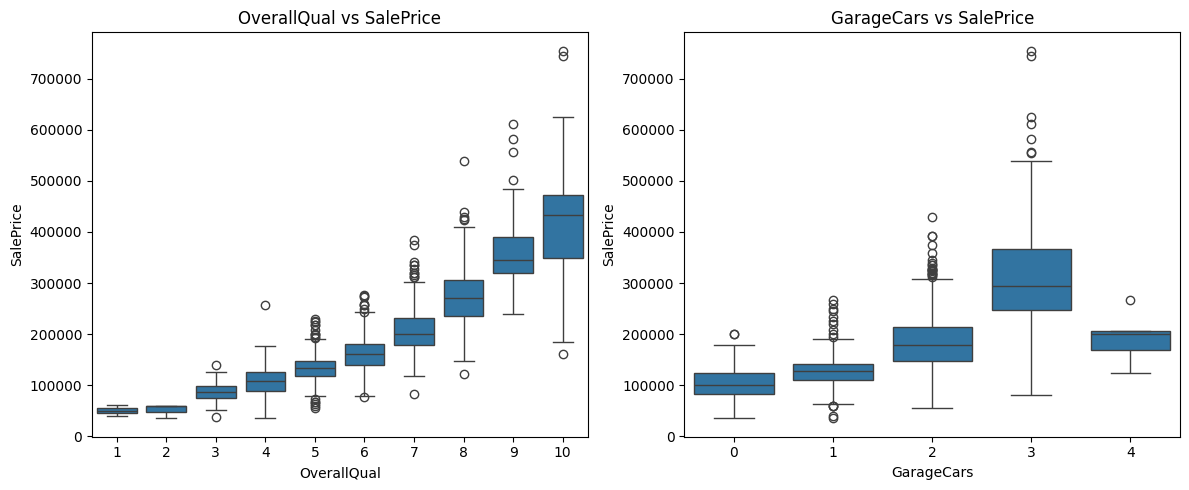

In [19]:
# boxplot of OverallQual and GarageCars with SalePrice
box_features = ['OverallQual', 'GarageCars']

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

for i, features in enumerate(box_features):
    sns.boxplot(data=train, x=features, y='SalePrice', ax=axes[i])
    axes[i].set_title(f"{features} vs SalePrice")

plt.tight_layout()
plt.show()

C:\Users\DELL 7480\AppData\Local\Temp\ipykernel_10516\2570436393.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_df = train.select_dtypes(include=['object'])


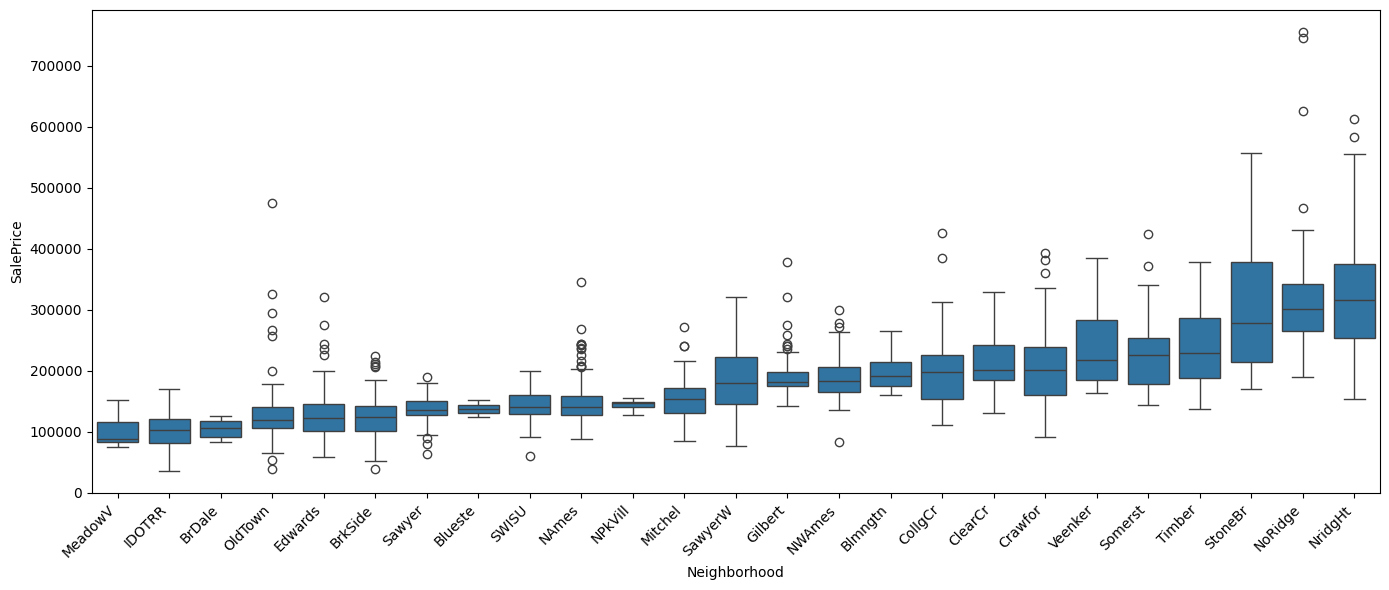

In [20]:
# Select only categorical features
cat_df = train.select_dtypes(include=['object'])

neighborhood_order = train.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(14, 6))

sns.boxplot(
    x=train["Neighborhood"],
    y=train["SalePrice"],
    order=neighborhood_order,
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

- House prices differ substantially across neighborhoods. Neighborhood is likely an important categorical predictor of SalePrice.

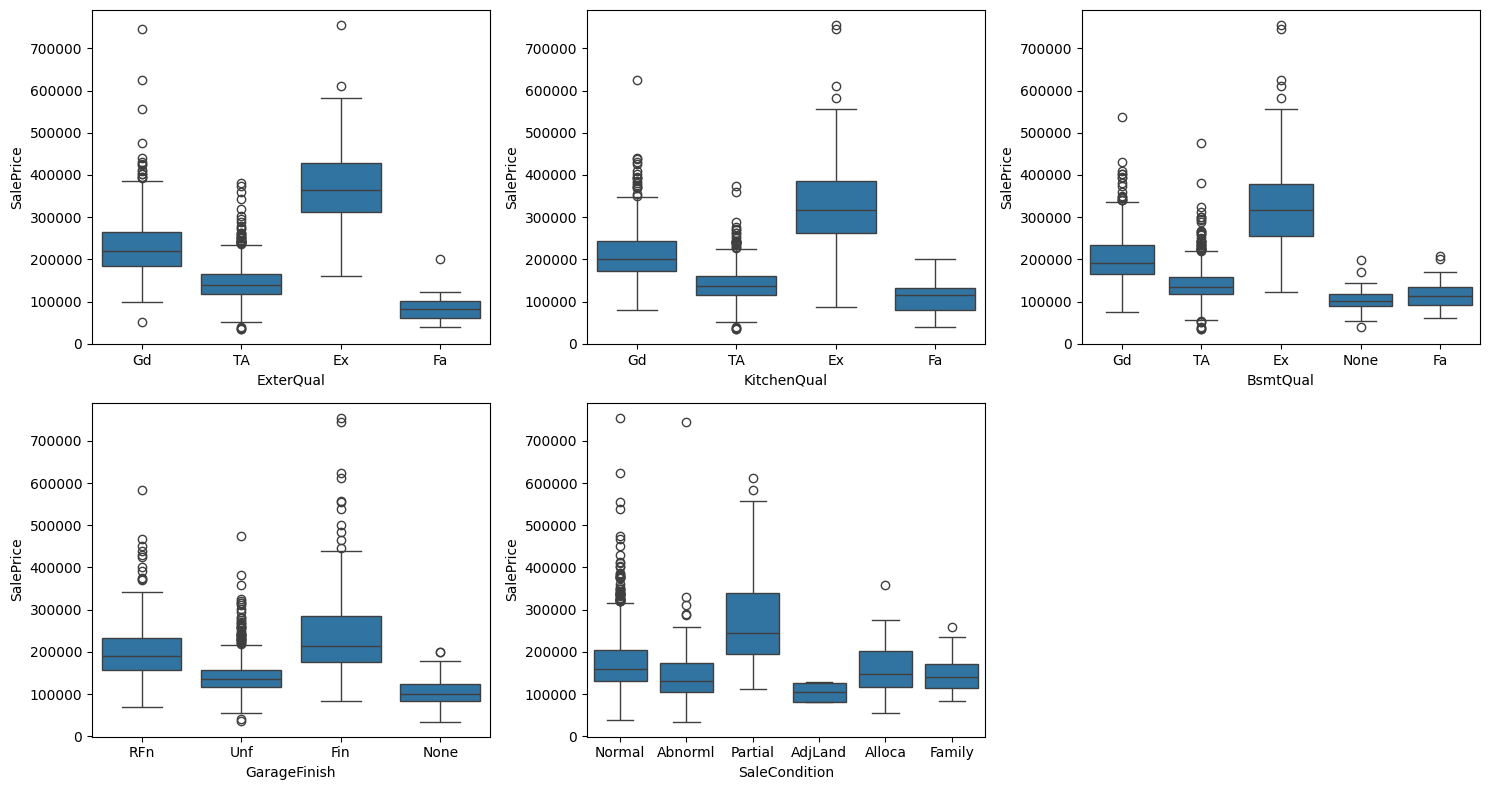

In [21]:
features = ['ExterQual', 'KitchenQual', 'BsmtQual', 'GarageFinish', 'SaleCondition']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, feature in enumerate(features):
    sns.boxplot(x = feature, y = 'SalePrice', data = train, ax=axes[i])

axes[-1].axis('off')  # Turn off the last empty subplot
plt.tight_layout()
plt.show()

#### Feature Engineering

In [22]:
# make pipeline of feature engineering
fe_pipeline = Pipeline([
    ("TotalSF", FunctionTransformer(lambda x: x.assign(TotalSF=x['TotalBsmtSF'] + x['1stFlrSF'] + x['2ndFlrSF']))),
    ("HouseAge", FunctionTransformer(lambda x: x.assign(HouseAge=x['YrSold'] - x['YearBuilt']))),
    ("RemodAge", FunctionTransformer(lambda x: x.assign(RemodAge=x['YrSold'] - x['YearRemodAdd']))),
    ("GarageAge", FunctionTransformer(lambda x: x.assign(GarageAge=x['YrSold'] - x['GarageYrBlt']))),
    ("TotalBathrooms", FunctionTransformer(lambda x: x.assign(TotalBathrooms=(x['FullBath'] + (0.5 * x['HalfBath']) + x['BsmtFullBath'] + (0.5 * x['BsmtHalfBath'])))))
])

# apply the feature engineering pipeline to the train dataset
train = fe_pipeline.fit_transform(train)

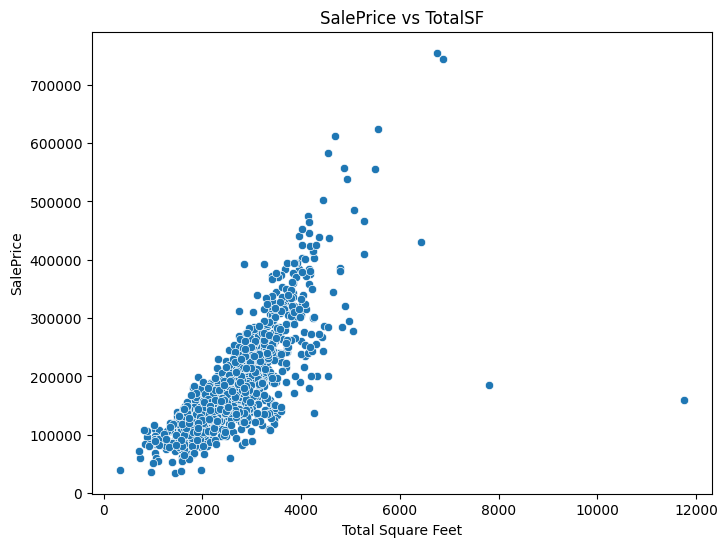

In [23]:
# saleprice Vs TotalSF correlation
plt.figure(figsize=(8, 6))
sns.scatterplot(x='TotalSF', y='SalePrice', data=train)
plt.title('SalePrice vs TotalSF')
plt.xlabel('Total Square Feet')
plt.ylabel('SalePrice')
plt.show()

- These two observations are unusually large relative to their sale prices. They are retained rather than removed based only on the target value, and their effect is left to model validation.

### Train / Validation Split

In [24]:
X = train.drop(columns=['SalePrice', 'Id'])
y = train['SalePrice']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print('X_train shape:', X_train.shape)
print('X_val shape:', X_val.shape)
print('y_train shape:', y_train.shape)
print('y_val shape:', y_val.shape)

X_train shape: (1168, 84)
X_val shape: (292, 84)
y_train shape: (1168,)
y_val shape: (292,)


#### Preprocessing Pipeline

In [25]:
numeric_cols = X_train.select_dtypes(include=[np.number]).columns

categorical_cols = X_train.select_dtypes(include=['object']).columns

numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median'))])

categorial_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer([('numeric', numeric_pipeline), ('categorical', categorial_pipeline)])

C:\Users\DELL 7480\AppData\Local\Temp\ipykernel_10516\3356667547.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns


#### Linear Regression Model

In [26]:
linear_pipeline = Pipeline([('preprocessor', preprocessor), ('model', LinearRegression())])

# Baseline: preprocessing + Linear Regression
# ColumnTransformer requires (name, transformer, columns)
preprocessor = ColumnTransformer([
	('numeric', numeric_pipeline, numeric_cols),
	('categorical', categorial_pipeline, categorical_cols)
])

linear_pipeline = Pipeline([
	('preprocessor', preprocessor),
	('model', LinearRegression())
])

linear_pipeline.fit(X_train, y_train)

y_pred = linear_pipeline.predict(X_val)

rmse_lr = root_mean_squared_error(y_val, y_pred)
rmsle_lr = root_mean_squared_log_error(y_val, y_pred)

print(f"RMSE Linear Regression: {rmse_lr:.2f}")
print(f"RMSLE Linear Regression: {rmsle_lr:.2f}")

RMSE Linear Regression: 31161.55
RMSLE Linear Regression: 0.17


In [27]:
numeric_pipeline_scaled = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

preprocessor_scaled = ColumnTransformer([('numeric', numeric_pipeline_scaled, numeric_cols),
    ('categorical', categorial_pipeline, categorical_cols)])

linear_pipeline_scaled = Pipeline([('preprocessor', preprocessor_scaled), ('model', LinearRegression())])

y_train_log = np.log1p(y_train)

linear_pipeline_scaled.fit(X_train, y_train_log)

y_pred_log = linear_pipeline_scaled.predict(X_val)
y_pred_linear = np.expm1(y_pred_log)

rmse_log_target = root_mean_squared_error(y_val, y_pred_linear)

rmsle_log_target = root_mean_squared_log_error(y_val, y_pred_linear)

print(f"RMSE with log target: {rmse_log_target:.2f}")
print(f"RMSLE with log target: {rmsle_log_target:.2f}")

RMSE with log target: 22877.35
RMSLE with log target: 0.13


#### ElasticNet Model

In [28]:
elasticnet_pipeline = Pipeline([('preprocessor', preprocessor_scaled), ('model', ElasticNet(max_iter=100000))])

param_grid = {
    'model__alpha': [0.0001, 0.0003, 0.0005, 0.0007, 0.001, 0.0015],
    'model_l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}

elasticnet_grid = GridSearchCV(estimator = elasticnet_pipeline, param_grid = param_grid, cv = 5, scoring='neg_root_mean_squared_error', n_jobs=-1)

# Correct the pipeline parameter name: model__l1_ratio
param_grid['model__l1_ratio'] = param_grid.pop('model_l1_ratio')
elasticnet_grid.param_grid = param_grid

elasticnet_grid.fit(X_train, y_train_log)

print('Best parameters found: ', elasticnet_grid.best_params_)
print('Best CV Log RMSE: ', -elasticnet_grid.best_score_)

Best parameters found:  {'model__alpha': 0.0015, 'model__l1_ratio': 0.7}
Best CV Log RMSE:  0.14415109778312946


In [29]:
best_elasticnet_model = elasticnet_grid.best_estimator_

y_pred_elasticnet_log = best_elasticnet_model.predict(X_val)
y_pred_elasticnet = np.expm1(y_pred_elasticnet_log)

rmse_elasticnet = root_mean_squared_error(y_val, y_pred_elasticnet)
rmsle_elasticnet = root_mean_squared_log_error(y_val, y_pred_elasticnet)

print(f"Validation RMSE ElasticNet: {rmse_elasticnet:.2f}")
print(f"Validation RMSLE ElasticNet: {rmsle_elasticnet:.2f}")

Validation RMSE ElasticNet: 25505.82
Validation RMSLE ElasticNet: 0.14


#### Ridge Model

In [30]:
ridge_pipeline = Pipeline([('preprocessor', preprocessor_scaled), ('model', Ridge())])

ridge_params = {'model__alpha': [0.1, 1, 3, 5, 10, 20, 50, 100]}

ridge_grid = GridSearchCV(estimator=ridge_pipeline, param_grid=ridge_params, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)


ridge_grid.fit(X_train, y_train_log)

print('Best parameters found: ', ridge_grid.best_params_)
print('Best CV Log RMSE: ', -ridge_grid.best_score_)

Best parameters found:  {'model__alpha': 20}
Best CV Log RMSE:  0.14462163739836126


In [31]:
best_ridge_model = ridge_grid.best_estimator_

y_pred_ridge_log = best_ridge_model.predict(X_val)
y_pred_ridge = np.expm1(y_pred_ridge_log)

rmse_ridge = root_mean_squared_error(y_val, y_pred_ridge)
rmsle_ridge = root_mean_squared_log_error(y_val, y_pred_ridge)

print(f"Validation RMSE Ridge: {rmse_ridge:.2f}")
print(f"Validation RMSLE Ridge: {rmsle_ridge:.2f}")

Validation RMSE Ridge: 25494.06
Validation RMSLE Ridge: 0.14


#### Lasso Model

In [32]:
lasso_pipeline = Pipeline([('preprocessor', preprocessor_scaled), ('model', Lasso(max_iter=100000))])

lasso_params = {'model__alpha': [0.0001, 0.0003, 0.0005, 0.0007, 0.001, 0.0015, 0.002]}

lasso_grid = GridSearchCV(estimator=lasso_pipeline, param_grid=lasso_params, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)

lasso_grid.fit(X_train, y_train_log)

print('Best parameters found: ', lasso_grid.best_params_)
print('Best CV Log RMSE: ', -lasso_grid.best_score_)

Best parameters found:  {'model__alpha': 0.0007}
Best CV Log RMSE:  0.1435773413419546


In [33]:
best_lasso = lasso_grid.best_estimator_

y_pred_lasso_log = best_lasso.predict(X_val)
y_pred_lasso = np.expm1(y_pred_lasso_log)

rmse_lasso = root_mean_squared_error(y_val, y_pred_lasso)
rmsle_lasso = root_mean_squared_log_error(y_val, y_pred_lasso)

print(f"Validation RMSE: {rmse_lasso:.2f}")
print(f"Validation RMSLE: {rmsle_lasso:.2f}")

Validation RMSE: 23578.73
Validation RMSLE: 0.13


#### Random Forest Pipeline

In [34]:
rf_pipeline = Pipeline([('preprocessor', preprocessor), ('model', RandomForestRegressor(random_state=42, n_jobs=-1))])

rf_params = {"model__n_estimators": [200, 400], 
             "model__max_depth": [None, 15, 25], 
             "model__min_samples_split": [2, 5], 
             "model_min_samples_leaf": [1, 2], 
             "model__max_features": ["sqrt", 0.7]}

rf_random = RandomizedSearchCV(estimator=rf_pipeline, 
                               param_distributions=rf_params,
                               n_iter=8, 
                               cv=3, 
                               scoring='neg_root_mean_squared_error', 
                               n_jobs=-1, verbose=1)

rf_params["model__min_samples_leaf"] = rf_params.pop("model_min_samples_leaf")

rf_random.fit(X_train, y_train_log)

print('Best parameters found: ', rf_random.best_params_)
print('Best CV Log RMSE: ', -rf_random.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters found:  {'model__n_estimators': 400, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 25}
Best CV Log RMSE:  0.1383133542704246


In [35]:
best_rf = rf_random.best_estimator_

y_pred_rf_log = best_rf.predict(X_val)
y_pred_rf = np.expm1(y_pred_rf_log)

rmse_rf = root_mean_squared_error(y_val, y_pred_rf)
rmsle_rf = root_mean_squared_log_error(y_val, y_pred_rf)

print(f"Validation RMSE Random Forest: {rmse_rf:.2f}")
print(f"Validation RMSLE Random Forest: {rmsle_rf:.2f}")

Validation RMSE Random Forest: 30322.89
Validation RMSLE Random Forest: 0.15


#### XGBoost Pipeline

In [36]:
xgb_pipeline = Pipeline([('preprocessor', preprocessor), ('model', XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1))])

xgb_params = {
    "model__n_estimators": [200, 300, 500, 800],
    "model__learning_rate": [0.01, 0.3, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.6, 0.8, 1],
    "model__colsample_bytree": [0.6, 0.8, 1]
}

xgb_random = RandomizedSearchCV(estimator=xgb_pipeline,
                                param_distributions=xgb_params,
                                n_iter=20,
                                cv=3,
                                scoring='neg_root_mean_squared_error',
                                n_jobs=-1, verbose=1, random_state=42)

xgb_random.fit(X_train, y_train_log)

print('Best parameters found: ', xgb_random.best_params_)
print('Best CV Log RMSE: ', -xgb_random.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters found:  {'model__subsample': 0.8, 'model__n_estimators': 800, 'model__min_child_weight': 3, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1}
Best CV Log RMSE:  0.12448800491658991


In [37]:
best_xgb = rf_random.best_estimator_

y_pred_xgb_log = best_xgb.predict(X_val)
y_pred_xgb = np.expm1(y_pred_xgb_log)

rmse_xgb = root_mean_squared_error(y_val, y_pred_xgb)
rmsle_xgb = root_mean_squared_log_error(y_val, y_pred_xgb)

print(f"Validation RMSE XGBoost: {rmse_xgb:.2f}")
print(f"Validation RMSLE XGBoost: {rmsle_xgb:.2f}")

Validation RMSE XGBoost: 30322.89
Validation RMSLE XGBoost: 0.15


In [38]:
xgb_grid_params = {'model__n_estimators': [700, 800, 900],
                   'model__learning_rate': [0.01, 0.05, 0.1],
                   'model__max_depth': [3, 4, 5],
                   'model__min_child_weight': [3, 5],
                   'model__subsample': [0.8, 0.9],
                   'model__colsample_bytree': [0.8, 0.85, 0.9]}

xgb_grid = GridSearchCV(estimator=xgb_pipeline,
                        param_grid=xgb_grid_params,
                        scoring='neg_root_mean_squared_error',
                        cv = 3,
                        n_jobs=-1, verbose=1)

xgb_grid.fit(X_train, y_train_log)

print('Best parameters found: ', xgb_grid.best_params_)
print('Best CV Log RMSE: ', -xgb_grid.best_score_)

Fitting 3 folds for each of 324 candidates, totalling 972 fits
Best parameters found:  {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__min_child_weight': 3, 'model__n_estimators': 900, 'model__subsample': 0.8}
Best CV Log RMSE:  0.12445668175270856


- A promising hyperparameter region was identified using RandomizedSearch. This region was subsequently refined through a more focused GridSearch. The refined XGBoost model emerged as one of the strongest performers in terms of validation RMSLE.

#### LightGBM Regressor

In [39]:
lgbm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMRegressor(
        objective='regression',
        random_state=42,
        n_jobs=-1,
        verbosity=1,
        subsample_frequency=1,
    ))
])

lgbm_params = {
    'model__n_estimators': [300, 500, 800, 1200],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__num_leaves': [15, 31, 63],
    'model__max_depth': [2, 3, 4, 5],
    'model__min_child_samples': [10, 20, 30],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.7, 0.85, 1.0]
}

lgbm_random = RandomizedSearchCV(estimator=lgbm_pipeline,
                                 param_distributions=lgbm_params,
                                 n_iter=20,
                                 cv = 3,
                                 scoring='neg_root_mean_squared_error',
                                 n_jobs=-1, verbose=0, random_state=42)

lgbm_random.fit(X_train, y_train_log)

print('Best parameters found: ', lgbm_random.best_params_)
print('Best CV Log RMSE: ', -lgbm_random.best_score_)

[LightGBM] [Warning] Unknown parameter: subsample_frequency
[LightGBM] [Warning] Unknown parameter: subsample_frequency
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004394 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3798
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 225
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [

In [40]:
best_lgbm = lgbm_random.best_estimator_

y_pred_lgbm_log = best_lgbm.predict(X_val)
y_pred_lgbm = np.expm1(y_pred_lgbm_log)

rmse_lgbm = root_mean_squared_error(y_val, y_pred_lgbm)
rmsle_lgbm = root_mean_squared_log_error(y_val, y_pred_lgbm)

print(f"Validation RMSE LightGBM: {rmse_lgbm}")
print(f"Validation RMSLE LightGBM: {rmsle_lgbm}")

[LightGBM] [Warning] Unknown parameter: subsample_frequency
Validation RMSE LightGBM: 29889.450856352432
Validation RMSLE LightGBM: 0.1338106421800202


#### CatBoost Regressor

In [41]:
catboost_model = CatBoostRegressor(
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

cat_features = list(categorical_cols)

catboost_model.fit(X_train, y_train_log, cat_features=cat_features)

y_pred_catboost_log = catboost_model.predict(X_val)
y_pred_catboost = np.expm1(y_pred_catboost_log)

rmse_catboost = root_mean_squared_error(y_val, y_pred_catboost)
rmsle_catboost = root_mean_squared_log_error(y_val, y_pred_catboost)

print(f"Validation RMSE CatBoost: {rmse_catboost}")
print(f"Validation RMSLE CatBoost: {rmsle_catboost}")

Validation RMSE CatBoost: 28469.44083335874
Validation RMSLE CatBoost: 0.1307146275796412


In [42]:
best_catboost_model = catboost_model

y_pred_catboost_log = best_catboost_model.predict(X_val)
y_pred_catboost = np.expm1(y_pred_catboost_log)

rmse_catboost = root_mean_squared_error(y_val, y_pred_catboost)
rmsle_catboost = root_mean_squared_log_error(y_val, y_pred_catboost)

print(f"Validation RMSE CatBoost: {rmse_catboost}")
print(f"Validation RMSLE CatBoost: {rmsle_catboost}")

Validation RMSE CatBoost: 28469.44083335874
Validation RMSLE CatBoost: 0.1307146275796412


In [43]:
catboost_grid = GridSearchCV(estimator=catboost_model,
                             param_grid={
                                 "learning_rate": [0.01, 0.1, 0.2],
                                 "n_estimators": [100, 200, 300],
                                 "max_depth": [3, 5, 7],
                                 "subsample": [0.5, 0.8, 1.0],
                                 "colsample_bylevel": [0.5, 0.8, 1.0]
                             },
                                scoring='neg_root_mean_squared_error',
                                cv=3, n_jobs=-1, verbose=1)

catboost_grid.fit(X_train, y_train_log, cat_features=cat_features)

print('Best parameters found: ', catboost_grid.best_params_)
print('Best CV Log RMSE: ', -catboost_grid.best_score_)

Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best parameters found:  {'colsample_bylevel': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Best CV Log RMSE:  0.12340032943623623


#### Model Comparison

Now we will compare the performance of all the models we have built so far. We will use the validation RMSLE as the metric for comparison.

In [44]:
results = {'Model' : [
    'Linear Regression',
    'ElasticNet',
    'Ride',
    'Lasso',
    'RandomForest',
    'XGBoost',
    'LightGBM',
    'CatBoost'],

    "Validation RMSLE": [
        rmsle_lr,
        rmsle_elasticnet,
        rmsle_ridge,
        rmsle_lasso,
        rmsle_rf,
        rmsle_xgb,
        rmsle_lgbm,
        rmsle_catboost]}

results_df = pd.DataFrame(results).sort_values(by='Validation RMSLE', ascending=True).reset_index(drop=True)

results_df

,Model,Validation RMSLE
0,CatBoost,0.130715
1,LightGBM,0.133811
2,Lasso,0.134796
3,Ride,0.137993
4,ElasticNet,0.139167
5,XGBoost,0.145744
6,RandomForest,0.145744
7,Linear Regression,0.168794


In [55]:
best_model = results_df['Model'][0]
best_model

'CatBoost'

In [56]:
from IPython.display import display, Markdown
display(Markdown(f"The Lower the RMSLE, the better the model performance."))

display(Markdown(f"\n**{best_model} has the best Validation Score.**"))
display(Markdown(f"Lasso and Ridge have surprisingly good performance.**"))
display(Markdown(f"Random Forest and Linear Regression have noticealy weaker performance.**"))

The Lower the RMSLE, the better the model performance.


**CatBoost has the best Validation Score.**

Lasso and Ridge have surprisingly good performance.**

Random Forest and Linear Regression have noticealy weaker performance.**

So we select {best_model} as our final model and will use it to make predictions on the test dataset. 

#### Error Analysis

In [45]:
error_df = X_val.copy()

error_df['ActualPrice'] = y_val
error_df['PredictedPrice'] = y_pred_catboost

error_df['LogError'] = (np.log1p(error_df['ActualPrice']) - np.log1p(error_df['PredictedPrice']).abs())

error_df['Residual'] = error_df['ActualPrice'] - error_df['PredictedPrice']

error_df.sort_values(by='LogError', ascending=False)[
    ['ActualPrice', 'PredictedPrice', 'LogError', 'OverallQual', 
     'GrLivArea', 'YearBuilt', 'Neighborhood']].head(10)

,ActualPrice,PredictedPrice,LogError,OverallQual,GrLivArea,YearBuilt,Neighborhood
691,755000,511923.022873,0.388543,10,4316,1994,NoRidge
898,611657,431164.950235,0.349680,9,2364,2009,NridgHt
218,311500,225676.965469,0.322293,7,1954,1939,Crawfor
774,395000,287490.583593,0.317695,8,1973,2006,NridgHt
277,141000,109091.230087,0.256573,4,864,1951,Gilbert
1046,556581,444718.994268,0.224370,9,2868,2005,StoneBr
607,225000,180240.741568,0.221806,5,2008,1948,Edwards
365,147000,121033.643328,0.194363,5,1344,1920,IDOTRR
451,280000,235381.832745,0.173580,7,1533,1975,ClearCr
669,137500,116359.781768,0.166936,4,1180,1922,Crawfor


In [46]:
error_df["PriceGroup"] = pd.qcut(
    error_df["ActualPrice"],
    q=4,
    labels=["Low", "Mid-Low", "Mid-High", "High"]
)

error_df.groupby(
    "PriceGroup",
    observed=True
).agg(
    Count=("ActualPrice", "size"),
    MeanActual=("ActualPrice", "mean"),
    MeanPredicted=("PredictedPrice", "mean"),
    MeanResidual=("Residual", "mean"),
    MeanLogError=("LogError", "mean")
)

,Count,MeanActual,MeanPredicted,MeanResidual,MeanLogError
PriceGroup,,,,,
Low,75,101607.413333,107207.748584,-5600.335250,-0.067301
Mid-Low,71,139672.633803,140000.751578,-328.117775,0.002915
Mid-High,73,179376.356164,181368.800116,-1992.443952,-0.006236
High,73,295745.726027,285291.172346,10454.553682,0.028249


Low -> Negative Residual Mid -> Lower error High -> Positive Residual

Since our residual definition is `Actual - Predicted`
- Negative residual means that the model over-predicted the sale price, 
- Positive residual means that the model under-predicted the sale price.

So model pulling edges to the center
- cheap houses are over-predicted
- expensive houses are under-predicted.

That's classical regression-to-the-mean behavior.

#### Conclusion
- Worst relative errors mostly occur for the unusual cheapest houses, which are over-predicted.
- Middle price range houses are predicted well, with low relative errors.
- Low price range houses tend to be over-predicted.
- High price range houses tend to be under-predicted
- This suggests regression towards the mean.

No new feature decisions were made solely from the holdout analysis.

#### Feature Importance

In [47]:
import pandas as pd

# 1. Get the trained CatBoost model
catboost_model = best_catboost_model

# 2. Get feature names
feature_names = X_train.columns.tolist()

# 3. Get feature importance
feature_importances = catboost_model.get_feature_importance()

# 4. Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# 5. Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# 6. Display top 20 features
importance_df.head(20)

,Feature,Importance
0,TotalSF,18.256524
1,OverallQual,13.735751
2,GrLivArea,5.316159
3,LotArea,3.240182
4,KitchenQual,3.203066
5,Fireplaces,3.083275
6,TotalBathrooms,2.997960
7,GarageFinish,2.932772
8,OverallCond,2.892877
9,1stFlrSF,2.638606


- `TotalSF`, `OverallQual`, `KitchenQual` and several other quality / category features rank high.

In [48]:
perm_result = permutation_importance(best_xgb, X_val, np.log1p(y_val), scoring="neg_root_mean_squared_error",
    n_repeats=10, random_state=42, n_jobs=-1)

perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

perm_df.head(20)

,Feature,Importance,Std
0,TotalSF,0.139153,0.004646
1,OverallQual,0.085767,0.002607
2,GrLivArea,0.008746,0.000775
3,CentralAir,0.006723,0.000470
4,GarageCars,0.004949,0.000364
5,YearBuilt,0.003889,0.000943
6,OverallCond,0.003749,0.000573
7,HouseAge,0.003594,0.000928
8,TotalBathrooms,0.003503,0.000698
9,LotArea,0.003370,0.000759


In [53]:
engineered_features = ["TotalSF", "HouseAge", "RemodAge", "GarageAge", "TotalBathrooms"]

tuned_catboost_params = {
    key.replace("model__", ""): value
    for key, value in catboost_grid.best_params_.items()
}

ablation_results = {}

# Full feature set
full_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        objective="reg:squarederror",
        random_state=42,
        **tuned_catboost_params
    ))
])

tuned_catboost_params = {
    key.replace("model__", ""): value
    for key, value in catboost_grid.best_params_.items()
}

ablation_results = {}

full_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        loss_function="RMSE",
        random_seed=42,
        verbose=0,
        **tuned_catboost_params
    ))
])

full_scores = cross_val_score(
    full_model,
    X_train,
    y_train_log,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

ablation_results["All features"] = -full_scores.mean()

ablation_results["All features"] = -full_scores.mean()

# Remove engineered features one by one
for feature in engineered_features:
    X_train_ablation = X_train.drop(columns=[feature])

    catboost_ablation = Pipeline([
        ("preprocessor", ColumnTransformer([
            (
                "numeric",
                numeric_pipeline,
                X_train_ablation.select_dtypes(
                    include=["number"]
                ).columns
            ),
            (
                "categorical",
                categorial_pipeline,
                X_train_ablation.select_dtypes(
                    include=["object"]
                ).columns
            )
        ])),
        ("model", CatBoostRegressor(
            objective="reg:squarederror",
            random_state=42,
            **tuned_catboost_params
        ))
    ])

    tuned_catboost_params = {
        key.replace("model__", ""): value
        for key, value in catboost_grid.best_params_.items()
    }

    # Remove objectives inherited from an XGBoost-style parameter grid
    tuned_catboost_params.pop("objective", None)
    tuned_catboost_params.pop("loss_function", None)

    ablation_results = {}

    for feature in engineered_features:
        X_train_ablation = X_train.drop(columns=[feature])

        ablation_preprocessor = ColumnTransformer([
            (
                "numeric",
                numeric_pipeline,
                X_train_ablation.select_dtypes(include=["number"]).columns
            ),
            (
                "categorical",
                categorial_pipeline,
                X_train_ablation.select_dtypes(include=["object"]).columns
            )
        ])

        catboost_ablation = Pipeline([
            ("preprocessor", ablation_preprocessor),
            ("model", CatBoostRegressor(
                loss_function="RMSE",
                random_seed=42,
                verbose=0,
                **tuned_catboost_params
            ))
        ])

        scores = cross_val_score(
            catboost_ablation,
            X_train_ablation,
            y_train_log,
            scoring="neg_root_mean_squared_error",
            cv=3,
            n_jobs=-1
        )

        ablation_results[f"Without {feature}"] = -scores.mean()

    pd.Series(ablation_results).sort_values()

    ablation_results[f"Without {feature}"] = -scores.mean()

pd.Series(ablation_results).sort_values()

C:\Users\DELL 7480\AppData\Local\Temp\ipykernel_10516\2644545981.py:66: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train_ablation.select_dtypes(
C:\Users\DELL 7480\AppData\Local\Temp\ipykernel_10516\2644545981.py:101: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-

Without TotalBathrooms    0.122802
Without GarageAge         0.124551
Without RemodAge          0.125060
Without TotalSF           0.126437
Without HouseAge          0.126771
dtype: float64

Now we will apply all the preprocessing, feature engineering, and model training steps to the test dataset and make predictions on the sale prices of the houses in the test dataset.

In [63]:

# Load Test Data
test = pd.read_csv("test.csv")

# Handle Missing Values
test = handle_missing_values(test)[0]

# Apply Feature Engineering
test = fe_pipeline.transform(test)

# Align Features with Training Data
test_features = test.drop(columns=["Id"], errors="ignore")
test_features = test_features.reindex(columns=X_train.columns)

# Generate Predictions
test_predictions_log = best_catboost_model.predict(test_features)

# Convert log predictions to original SalePrice scale
test_predictions = np.expm1(test_predictions_log)

# Create Submission File
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

# Save Submission
submission.to_csv("submission.csv", index=False)

# Preview Submission
display(submission.head())

print("Submission file created successfully!")
print(f"Submission shape: {submission.shape}")

,Id,SalePrice
0,1461,126202.413736
1,1462,155952.011233
2,1463,185863.659834
3,1464,194678.023851
4,1465,185038.032334


Submission file created successfully!
Submission shape: (1459, 2)


In [66]:
result = handle_missing_values(pd.read_csv("test.csv"))

print(type(result))
print(type(result[0]) if isinstance(result, tuple) else "Not a tuple")
print(len(result) if isinstance(result, tuple) else "Single object")

<class 'tuple'>
<class 'pandas.DataFrame'>
1


In [65]:
# Check submission structure
assert submission.shape[0] == len(test)
assert submission["Id"].is_unique
assert submission["SalePrice"].notna().all()
assert (submission["SalePrice"] > 0).all()

print("All submission checks passed!")

All submission checks passed!


We have solved the house price prediction problem using various regression models and feature engineering techniques. The CatBoost model emerged as the best performer based on validation RMSLE. We also conducted error analysis and feature importance analysis to understand the model's behavior and the key features influencing house prices.